# Reading charts in a RAG pipeline: OCR vs Vision Models


## 0. Setup

In [ ]:
import os, re, json, base64, time
from pathlib import Path

import numpy as np
import pandas as pd
import matplotlib
matplotlib.use("Agg")
import matplotlib.pyplot as plt
from scipy import stats

ROOT = Path(".")
CHART_DIR = ROOT / "charts"
RESULT_DIR = ROOT / "results"
CHART_DIR.mkdir(exist_ok=True)
(RESULT_DIR / "extractions").mkdir(parents=True, exist_ok=True)


GEMINI_API_KEY = os.getenv("GEMINI_API_KEY")


GEMINI_MODEL = os.getenv("GEMINI_MODEL", "gemini-4-carbon")

SIGNIFICANCE_LEVEL = 0.05
print("Gemini key found:", bool(GEMINI_API_KEY), "| model:", GEMINI_MODEL)

Gemini key found: True | model: gemini-4-carbon


## 1. Generate test charts with known answers

We create the data first, then draw the chart. Because we know the true slope and p-value, we can measure exactly how accurate each extraction method is. The charts **show** the p-value (as papers usually do) but **not** the slope, so the slope has to be recovered from the plotted points.

| Chart | What it tests |
|---|---|
| `strong_decline` | Clear negative trend, very small p-value |
| `no_effect` | Weak trend, not significant |
| `borderline` | p-value just under 0.05, where a misread flips the conclusion |
| `two_arm` | Treatment vs. placebo over time; p-value for the difference in slopes |

In [ ]:
def fmt_p(p):
    return "p < 0.001" if p < 0.001 else f"p = {p:.3f}"

def interaction_p(x, y, group):
    """p-value for the difference in slopes between two groups (OLS with an interaction term)."""
    X = np.column_stack([np.ones_like(x), x, group, x * group])
    beta, *_ = np.linalg.lstsq(X, y, rcond=None)
    resid = y - X @ beta
    dof = len(y) - X.shape[1]
    sigma2 = resid @ resid / dof
    cov = sigma2 * np.linalg.inv(X.T @ X)
    t = beta[3] / np.sqrt(cov[3, 3])
    return float(2 * stats.t.sf(abs(t), dof)), beta

def make_single(name, slope, intercept, noise, n=12, p_range=None, seed=0, xlabel="Dose (mg)", ylabel="Response (%)"):
    rng = np.random.default_rng(seed)
    while True:  # resample until the p-value lands in the requested range
        x = np.linspace(0, 10, n)
        y = intercept + slope * x + rng.normal(0, noise, n)
        lr = stats.linregress(x, y)
        if p_range is None or p_range[0] <= lr.pvalue <= p_range[1]:
            break
    fig, ax = plt.subplots(figsize=(6, 4), dpi=150)
    ax.scatter(x, y, color="#1f77b4", zorder=3, label="Observed")
    xs = np.linspace(x.min(), x.max(), 50)
    ax.plot(xs, lr.intercept + lr.slope * xs, color="#d62728", label="Linear fit")
    ax.set_xlabel(xlabel); ax.set_ylabel(ylabel)
    ax.set_title(name.replace("_", " ").title())
    ax.text(0.03, 0.05, fmt_p(lr.pvalue), transform=ax.transAxes, fontsize=11,
            bbox=dict(facecolor="white", edgecolor="gray"))
    ax.grid(alpha=0.3); ax.legend(loc="upper left", bbox_to_anchor=(1.01, 1))
    path = CHART_DIR / f"{name}.png"
    fig.tight_layout(); fig.savefig(path); plt.close(fig)
    return {
        "chart_id": name, "image": str(path), "type": "scatter_with_fit",
        "series": [{"name": "Observed", "points": [[round(float(a), 3), round(float(b), 3)] for a, b in zip(x, y)]}],
        "true_slope": {"Observed": float(lr.slope)},
        "true_p_value": float(lr.pvalue), "printed_p_text": fmt_p(lr.pvalue),
    }

def make_two_arm(name="two_arm", seed=7):
    rng = np.random.default_rng(seed)
    weeks = np.arange(0, 13, 2).astype(float)
    while True:
        treat = 50 - 2.6 * weeks + rng.normal(0, 2.0, len(weeks))
        plac = 50 - 0.4 * weeks + rng.normal(0, 2.0, len(weeks))
        x = np.concatenate([weeks, weeks]); y = np.concatenate([treat, plac])
        g = np.concatenate([np.ones_like(weeks), np.zeros_like(weeks)])
        p, _ = interaction_p(x, y, g)
        if p < 0.01:
            break
    fig, ax = plt.subplots(figsize=(6, 4), dpi=150)
    ax.plot(weeks, treat, "o-", color="#d62728", label="Treatment")
    ax.plot(weeks, plac, "s--", color="#7f7f7f", label="Placebo")
    ax.set_xlabel("Week"); ax.set_ylabel("Tumor size (mm)"); ax.set_title("Tumor Size Over Time")
    ax.text(0.03, 0.05, fmt_p(p) + " (difference in slopes)", transform=ax.transAxes, fontsize=10,
            bbox=dict(facecolor="white", edgecolor="gray"))
    ax.grid(alpha=0.3); ax.legend(loc="upper left", bbox_to_anchor=(1.01, 1))
    path = CHART_DIR / f"{name}.png"
    fig.tight_layout(); fig.savefig(path); plt.close(fig)
    return {
        "chart_id": name, "image": str(path), "type": "two_arm_lines",
        "series": [{"name": "Treatment", "points": [[float(a), round(float(b), 3)] for a, b in zip(weeks, treat)]},
                   {"name": "Placebo", "points": [[float(a), round(float(b), 3)] for a, b in zip(weeks, plac)]}],
        "true_slope": {"Treatment": float(stats.linregress(weeks, treat).slope),
                       "Placebo": float(stats.linregress(weeks, plac).slope)},
        "true_p_value": float(p), "printed_p_text": fmt_p(p),
    }

GROUND_TRUTH = [
    make_single("strong_decline", slope=-3.0, intercept=60, noise=3, seed=1, p_range=(0, 0.001)),
    make_single("no_effect", slope=0.3, intercept=40, noise=6, seed=2, p_range=(0.2, 0.6)),
    make_single("borderline", slope=1.2, intercept=30, noise=4.5, seed=3, p_range=(0.03, 0.049)),
    make_two_arm(),
]
(RESULT_DIR / "ground_truth.json").write_text(json.dumps(GROUND_TRUTH, indent=2))

pd.DataFrame([{
    "chart": g["chart_id"], "printed p": g["printed_p_text"],
    "significant (p<0.05)": g["true_p_value"] < SIGNIFICANCE_LEVEL,
    **{f"true slope: {k}": round(v, 3) for k, v in g["true_slope"].items()},
} for g in GROUND_TRUTH])

,chart,printed p,significant (p<0.05),true slope: Observed,true slope: Treatment,true slope: Placebo
0,strong_decline,p < 0.001,True,-2.986,NaN,NaN
1,no_effect,p = 0.305,False,0.671,NaN,NaN
2,borderline,p = 0.049,True,0.929,NaN,NaN
3,two_arm,p < 0.001,True,NaN,-2.692,-0.566


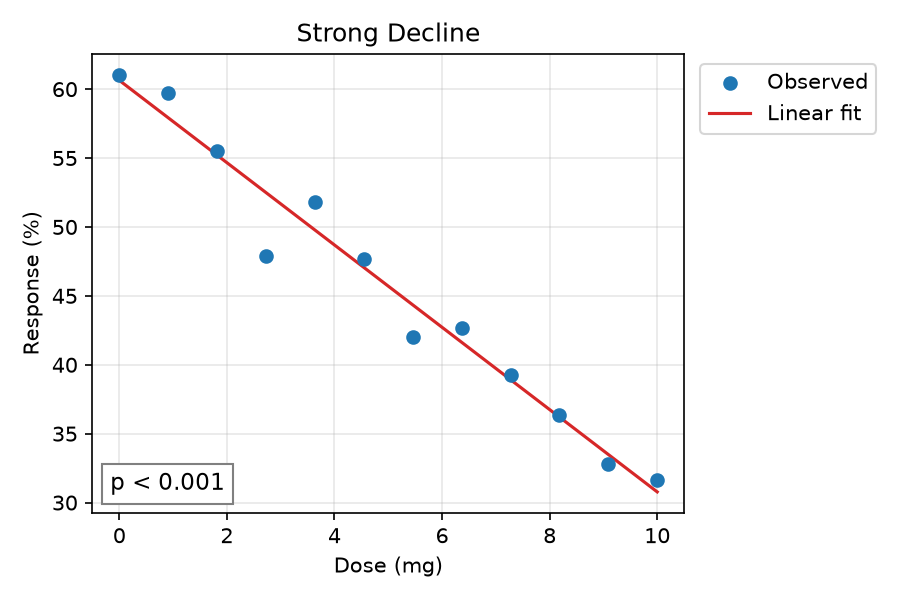

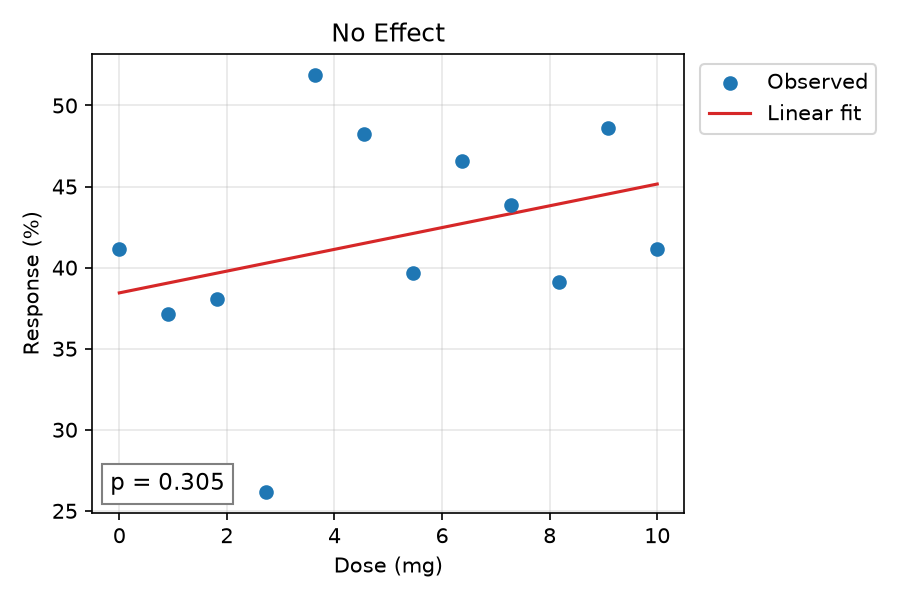

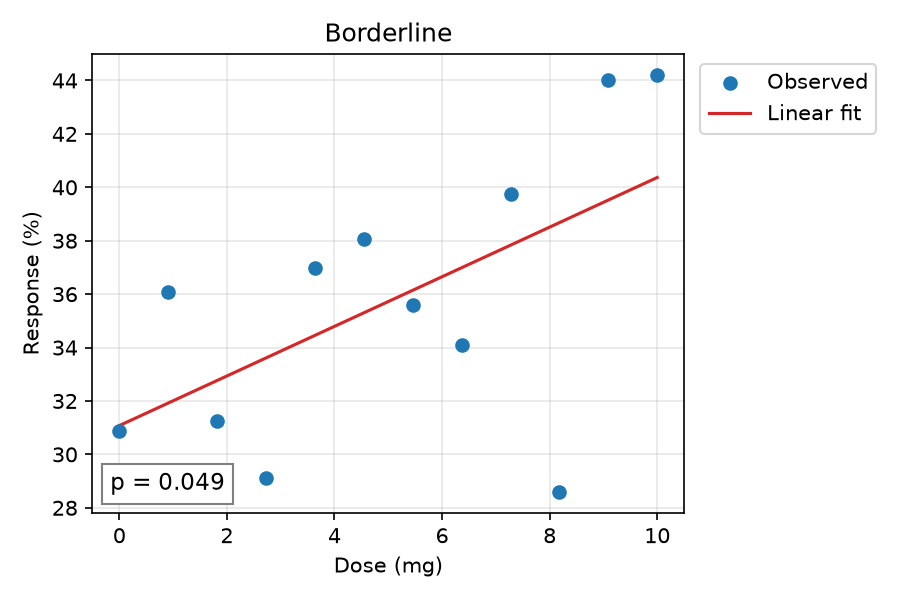

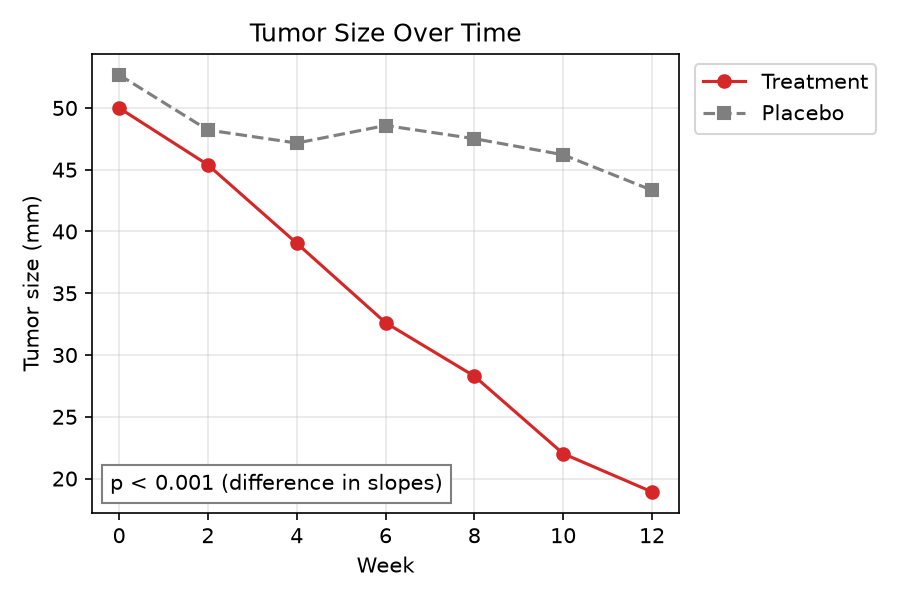

In [ ]:
from IPython.display import Image, display
for g in GROUND_TRUTH:
    display(Image(filename=g["image"], width=420))

## 2. Baseline: plain OCR

OCR (here, Tesseract) reads the **text** in an image. It picks up the axis labels, title, and the printed p-value, but it has no way to see the **trend**, so it can't recover the slope.

In [ ]:
import shutil
import pytesseract
from PIL import Image as PILImage

# Find the Tesseract program (it can be installed by Homebrew or conda in different places)
TESSERACT_PATH = shutil.which("tesseract") or next(
    (p for p in [
        "/opt/homebrew/bin/tesseract",
        "/usr/local/bin/tesseract",
        str(Path.home() / "miniconda3/bin/tesseract"),
        str(Path.home() / "anaconda3/bin/tesseract"),
    ] if Path(p).exists()), None)
if TESSERACT_PATH:
    pytesseract.pytesseract.tesseract_cmd = TESSERACT_PATH

P_PATTERN = re.compile(r"p\s*([<=])\s*([0-9]*\.?[0-9]+)", re.IGNORECASE)

def parse_p_text(text):
    """Find a printed p-value like 'p = 0.031' or 'p < 0.001' in free text."""
    if not text:
        return None
    m = P_PATTERN.search(text)
    if not m:
        return None
    op, val = m.group(1), m.group(2)
    return {"op": op, "value": float(val), "text": f"p {op} {val}"}

ocr_rows = []
if TESSERACT_PATH is None:
    print("Tesseract not found, so the OCR baseline is skipped. Install it with: brew install tesseract")
else:
    print("Using Tesseract at:", TESSERACT_PATH)
    for g in GROUND_TRUTH:
        text = pytesseract.image_to_string(PILImage.open(g["image"]))
        found = parse_p_text(text)
        ocr_rows.append({
            "chart": g["chart_id"],
            "OCR text (first 80 chars)": " ".join(text.split())[:80],
            "p-value read": found["text"] if found else None,
            "printed p": g["printed_p_text"],
            "slope recovered": "no (OCR can't see the trend)",
        })
pd.DataFrame(ocr_rows)

Using Tesseract at: /Users/mugilsuga/miniconda3/bin/tesseract


,chart,OCR text (first 80 chars),p-value read,printed p,slope recovered
0,strong_decline,Response (%) Strong Decline b o w uo 30+ 0 2 4...,NaN,p < 0.001,no (OCR can't see the trend)
1,no_effect,Response (%) No Effect p = 0.305 25 4 6 8 10 D...,p = 0.305,p = 0.305,no (OCR can't see the trend)
2,borderline,Response (%) Borderline a BR 5 N B 3 w 00 0 2 ...,NaN,p = 0.049,no (OCR can't see the trend)
3,two_arm,Tumor Size Over Time s —®@- Treatment “eee een...,p < 0.001,p < 0.001,no (OCR can't see the trend)


## 3. Vision-model extraction (Gemini 4 Carbon)

A newer vision-capable model, **Gemini 4 Carbon**, looks at each chart **once, at ingestion**, and returns structured JSON: axes, data points per series, the printed p-value **copied exactly**, and its own slope estimate. We ask for the model's slope estimate only so we can compare it with the slope computed in code.


In [ ]:
EXTRACTION_PROMPT = """You are extracting data from a scientific chart for a retrieval system.
Return ONLY valid JSON with this structure:
{
  "chart_type": string,
  "title": string,
  "x_axis": {"label": string, "unit": string or null},
  "y_axis": {"label": string, "unit": string or null},
  "series": [{"name": string, "points": [[x, y], ...]}],
  "p_value_text": string or null,
  "model_estimated_slope": {"<series name>": number},
  "confidence": "high" | "medium" | "low",
  "notes": string
}
Rules:
- Copy any printed p-value text EXACTLY as shown (e.g. "p = 0.031" or "p < 0.001"). Do not round or reinterpret it.
- Read each plotted data point's x and y from the axes as precisely as you can. Include every point you can see; do not invent points.
- For scatter plots with a fit line, report the scatter points, not the line.
- If something is unreadable, say so in "notes" and lower "confidence"."""

def image_b64(path):
    return base64.b64encode(Path(path).read_bytes()).decode()

def parse_json(text):
    text = text.strip()
    text = re.sub(r"^```(?:json)?|```$", "", text, flags=re.MULTILINE).strip()
    start, end = text.find("{"), text.rfind("}")
    return json.loads(text[start:end + 1])

def extract_with_gemini(path):
    from google import genai
    from google.genai import types
    client = genai.Client(api_key=GEMINI_API_KEY)
    resp = client.models.generate_content(
        model=GEMINI_MODEL,
        contents=[types.Part.from_bytes(data=Path(path).read_bytes(), mime_type="image/png"), EXTRACTION_PROMPT],
        config=types.GenerateContentConfig(temperature=0, response_mime_type="application/json"),
    )
    return parse_json(resp.text)

EXTRACTORS = {
    "gemini": (extract_with_gemini, GEMINI_API_KEY, GEMINI_MODEL),
}

def run_extractions():
    results = {}
    for name, (fn, key, model_id) in EXTRACTORS.items():
        cache_dir = RESULT_DIR / "extractions" / name
        cache_dir.mkdir(parents=True, exist_ok=True)
        for g in GROUND_TRUTH:
            cache = cache_dir / f"{g['chart_id']}.json"
            if cache.exists():
                results[(name, g["chart_id"])] = json.loads(cache.read_text())
                continue
            if not key:
                continue
            try:
                t0 = time.time()
                out = fn(g["image"])
                out["_meta"] = {"model": model_id, "seconds": round(time.time() - t0, 2)}
                cache.write_text(json.dumps(out, indent=2))
                results[(name, g["chart_id"])] = out
            except Exception as e:
                print(f"[{name}] {g['chart_id']} failed: {e}")
    return results

EXTRACTIONS = run_extractions()
print(f"{len(EXTRACTIONS)} extractions available:", sorted(EXTRACTIONS))
if not EXTRACTIONS:
    print("No extractions yet. Set GEMINI_API_KEY in your .env file and check the errors above, then re-run.")

4 extractions available: [('gemini', 'borderline'), ('gemini', 'no_effect'), ('gemini', 'strong_decline'), ('gemini', 'two_arm')]


## 4. Do the math in code, not in the model

LLMs are unreliable at arithmetic, and estimating a slope by "looking" at a picture compounds the error. So we take the **extracted points** and compute the slope with a standard linear regression (`scipy.stats.linregress`), then compare three numbers:

- **true slope** (from the data we generated),
- **model's eyeballed slope** (what the model claimed),
- **code-computed slope** (regression on the points the model extracted).

We also recompute the p-value from the extracted points. It usually **won't** match the printed one exactly, because small point-reading errors change the residuals. That's the key lesson: **use the printed p-value as the source of truth for significance, and use the points for the slope.**

In [ ]:
def code_slopes(extraction):
    out = {}
    for s in extraction.get("series", []):
        pts = np.array(s.get("points", []), dtype=float)
        if len(pts) >= 3:
            lr = stats.linregress(pts[:, 0], pts[:, 1])
            out[s["name"]] = {"slope": float(lr.slope), "p_from_points": float(lr.pvalue), "n_points": len(pts)}
    return out

def match_series(name, candidates, allow_single_fallback=True):
    """Match a series name from the model to a ground-truth name (case-insensitive, substring).
    If a chart has only one series, any name maps to it (models often label it differently)."""
    name_l = (name or "").lower()
    for c in candidates:
        if c.lower() == name_l or c.lower() in name_l or name_l in c.lower():
            return c
    return candidates[0] if (allow_single_fallback and len(candidates) == 1) else None

slope_rows = []
gt_by_id = {g["chart_id"]: g for g in GROUND_TRUTH}
for (model, chart_id), ex in sorted(EXTRACTIONS.items()):
    g = gt_by_id[chart_id]
    computed = code_slopes(ex)
    eyeballed = ex.get("model_estimated_slope") or {}
    for s_name, c in computed.items():
        gt_name = match_series(s_name, list(g["true_slope"]))
        if gt_name is None:
            continue
        true_s = g["true_slope"][gt_name]
        eye = next((v for k, v in eyeballed.items() if match_series(k, list(g["true_slope"])) == gt_name), None)
        slope_rows.append({
            "model": model, "chart": chart_id, "series": gt_name,
            "true slope": round(true_s, 3),
            "model eyeballed": round(float(eye), 3) if eye is not None else None,
            "code-computed": round(c["slope"], 3),
            "eyeball error %": round(abs(float(eye) - true_s) / abs(true_s) * 100, 1) if eye is not None and true_s else None,
            "code error %": round(abs(c["slope"] - true_s) / abs(true_s) * 100, 1) if true_s else None,
            "points read / true": f'{c["n_points"]}/{len(next(s for s in g["series"] if s["name"] == gt_name)["points"])}',
        })
SLOPES = pd.DataFrame(slope_rows)
SLOPES if not SLOPES.empty else print("Run the extraction step with an API key to populate this table.")

,model,chart,series,true slope,model eyeballed,code-computed,eyeball error %,code error %,points read / true
0,gemini,borderline,Observed,0.929,0.93,0.930,0.1,0.1,12/12
1,gemini,no_effect,Observed,0.671,0.67,0.671,0.2,0.0,12/12
2,gemini,strong_decline,Observed,-2.986,-2.99,-2.986,0.1,0.0,12/12
3,gemini,two_arm,Treatment,-2.692,-2.69,-2.693,0.1,0.0,7/7
4,gemini,two_arm,Placebo,-0.566,-0.56,-0.564,1.0,0.2,7/7


## 5. Validate every extraction

A misread p-value can flip a conclusion (0.031 vs. 0.31), so nothing goes into the knowledge base without checks. An extraction is **flagged for human review** if any of these fail:

| Check | Rule |
|---|---|
| p-value text | Printed p-value copied exactly |
| Significance | Same "significant / not significant" decision as the truth |
| Slope | Code-computed slope within 10% of the true slope, or 0.1 units for very flat lines (in production, without ground truth, you'd compare against a second model or a reviewer) |
| Point count | All plotted points found |
| Model confidence | Model did not report low confidence |

In [ ]:
SLOPE_TOLERANCE = 0.10      # relative: 10% of the true slope
SLOPE_ABS_FLOOR = 0.10      # absolute floor, so very flat slopes aren't flagged for tiny reading errors

def slope_ok_fn(computed, true_s):
    return abs(computed - true_s) <= max(SLOPE_TOLERANCE * abs(true_s), SLOPE_ABS_FLOOR)

def significant(p_info):
    if p_info is None:
        return None
    return p_info["value"] < SIGNIFICANCE_LEVEL if p_info["op"] == "=" else (p_info["op"] == "<" and p_info["value"] <= SIGNIFICANCE_LEVEL)

def validate(model, chart_id, ex):
    g = gt_by_id[chart_id]
    read_p = parse_p_text(ex.get("p_value_text"))
    true_p = parse_p_text(g["printed_p_text"])
    checks = {
        "p text exact": read_p is not None and read_p["text"] == true_p["text"],
        "significance correct": read_p is not None and significant(read_p) == (g["true_p_value"] < SIGNIFICANCE_LEVEL),
    }
    slope_ok, count_ok = True, True
    for s_name, c in code_slopes(ex).items():
        gt_name = match_series(s_name, list(g["true_slope"]))
        if gt_name is None:
            slope_ok = False; continue
        true_s = g["true_slope"][gt_name]
        slope_ok &= slope_ok_fn(c["slope"], true_s)
        true_n = len(next(s for s in g["series"] if s["name"] == gt_name)["points"])
        count_ok &= c["n_points"] == true_n
    checks["slope within tolerance"] = slope_ok and bool(code_slopes(ex))
    checks["all points found"] = count_ok and bool(code_slopes(ex))
    checks["confidence not low"] = ex.get("confidence", "low") != "low"
    passed = all(checks.values())
    return {"model": model, "chart": chart_id, **checks,
            "status": "validated" if passed else "NEEDS HUMAN REVIEW"}

VALIDATION = pd.DataFrame([validate(m, c, ex) for (m, c), ex in sorted(EXTRACTIONS.items())])
VALIDATION if not VALIDATION.empty else print("No extractions to validate yet.")

,model,chart,p text exact,significance correct,slope within tolerance,all points found,confidence not low,status
0,gemini,borderline,True,True,True,True,True,validated
1,gemini,no_effect,True,True,True,True,True,validated
2,gemini,strong_decline,True,True,True,True,True,validated
3,gemini,two_arm,True,True,True,True,True,validated


## 6. Mini RAG: answer questions from validated chart data

Each validated extraction becomes a knowledge-base record: a short text summary (for retrieval), the structured numbers (for answering), and a link back to the source image (for citation). Retrieval uses simple TF-IDF so the example runs anywhere; in production this would be the same vector or hybrid search used for the rest of the documents.

The answer is built from the **structured numbers**, not generated freely, and every answer cites the source chart. Charts that failed validation are not used to answer; they're surfaced as "needs review" instead.

In [ ]:
from sklearn.feature_extraction.text import TfidfVectorizer
from sklearn.metrics.pairwise import cosine_similarity

def summarize(chart_id, ex):
    slopes = code_slopes(ex)
    p = parse_p_text(ex.get("p_value_text"))
    parts = [f"Chart '{ex.get('title', chart_id)}' plots {ex.get('y_axis', {}).get('label', 'y')} "
             f"against {ex.get('x_axis', {}).get('label', 'x')}."]
    for name, c in slopes.items():
        trend = "increases" if c["slope"] > 0 else "decreases"
        parts.append(f"{name} {trend} with a slope of {c['slope']:.2f} per unit.")
    if p:
        parts.append(f"Reported {p['text']}, which is {'statistically significant' if significant(p) else 'not statistically significant'} at 0.05.")
    return " ".join(parts)

def build_kb(preferred_model=None):
    records = []
    for _, row in VALIDATION.iterrows():
        if preferred_model and row["model"] != preferred_model:
            continue
        ex = EXTRACTIONS[(row["model"], row["chart"])]
        records.append({"chart_id": row["chart"], "model": row["model"], "status": row["status"],
                        "image": gt_by_id[row["chart"]]["image"], "summary": summarize(row["chart"], ex)})
    return records

def answer(question, kb, top_k=1):
    if not kb:
        return "Knowledge base is empty: run the extraction step first."
    vec = TfidfVectorizer().fit([r["summary"] for r in kb] + [question])
    sims = cosine_similarity(vec.transform([question]), vec.transform([r["summary"] for r in kb]))[0]
    best = [kb[i] for i in np.argsort(sims)[::-1][:top_k]]
    lines = []
    for r in best:
        if r["status"] != "validated":
            lines.append(f"The most relevant chart ({r['chart_id']}) has NOT passed validation, so I won't state its numbers. "
                         f"It's been flagged for human review. Source: {r['image']}")
        else:
            lines.append(f"{r['summary']} [Source: {r['image']}, extracted by {r['model']}]")
    return "\n".join(lines)

if not VALIDATION.empty:
    KB = build_kb(preferred_model=VALIDATION["model"].iloc[0])
    for q in ["Did tumor size decrease faster with treatment than placebo, and is it significant?",
              "Is the dose response borderline significant?",
              "Is there any effect in the no effect study?"]:
        print("Q:", q); print("A:", answer(q, KB)); print()
else:
    print("Run the extraction step with an API key to build the knowledge base.")

Q: Did tumor size decrease faster with treatment than placebo, and is it significant?
A: Chart 'Tumor Size Over Time' plots Tumor size (mm) against Week. Treatment decreases with a slope of -2.69 per unit. Placebo decreases with a slope of -0.56 per unit. Reported p < 0.001, which is statistically significant at 0.05. [Source: charts/two_arm.png, extracted by gemini]

Q: Is the dose response borderline significant?
A: Chart 'Borderline' plots Response against Dose. Observed increases with a slope of 0.93 per unit. Reported p = 0.049, which is statistically significant at 0.05. [Source: charts/borderline.png, extracted by gemini]

Q: Is there any effect in the no effect study?
A: Chart 'No Effect' plots Response against Dose. Observed increases with a slope of 0.67 per unit. Reported p = 0.305, which is not statistically significant at 0.05. [Source: charts/no_effect.png, extracted by gemini]



## 7. Results summary

In [ ]:
if not VALIDATION.empty:
    check_cols = [c for c in VALIDATION.columns if c not in ("model", "chart", "status")]
    summary = VALIDATION.groupby("model")[check_cols].mean().mul(100).round(0).astype(int).astype(str) + "%"
    summary["validated charts"] = VALIDATION.groupby("model")["status"].apply(lambda s: f"{(s == 'validated').sum()}/{len(s)}")
    display(summary)
    if not SLOPES.empty:
        display(SLOPES.groupby("model")[["eyeball error %", "code error %"]].mean().round(1)
                .rename(columns={"eyeball error %": "avg slope error: model eyeballed (%)",
                                 "code error %": "avg slope error: computed in code (%)"}))
print("OCR baseline: read the printed p-value on",
      sum(r["p-value read"] == r["printed p"] for r in ocr_rows), "of", len(ocr_rows),
      "charts, and recovered the slope on 0 charts.")

,p text exact,significance correct,slope within tolerance,all points found,confidence not low,validated charts
model,,,,,,
gemini,100%,100%,100%,100%,100%,4/4


,avg slope error: model eyeballed (%),avg slope error: computed in code (%)
model,,
gemini,0.3,0.1


OCR baseline: read the printed p-value on 2 of 4 charts, and recovered the slope on 0 charts.
